<a href="https://colab.research.google.com/github/Swathi04705/APS/blob/main/APSrandvariable.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
#PROBLEM 1

**Step 1: Identify the random variable**

1. X=1
represents the customer clicks the promotional email link.

2. X=0
represents the customer does not click the link.

3. X∈{0,1}
So the possible values are 0 and 1.

 4. X is Discrete.

5.   The suitable distribution is the Bernoulli distribution.

$$ X\sim Bernoulli(0.30) $$

**Step 2: Theoretical PMF **

For \(X=0\)
 P(X=0)=1-p
  
   =1-0.30=0.70

For \(X=1\)
P(X=1)=p=0.30

**Step 3: Generate outcomes for 20 customers**





In [ ]:
import numpy as np

p = 0.30
sample_size = 20

samples = np.random.binomial(n=1, p=p, size=sample_size)

print(samples)

[0 0 0 0 1 0 0 1 0 0 0 0 1 1 0 1 1 0 1 0]


1. How many observations were generated?

20 observations.

2. What does each zero represent?

Each 0 represents a customer who did not click.

3. What does each one represent?

Each 1 represents a customer who clicked.

4. Are your generated observations the same as the theoretical probabilities?

Not necessarily.

The theoretical probability of a click is exactly 0.30, but the empirical probability from only 20 simulated customers may be different because of random variation.

**Step 4: Count clicks and non-clicks**

In [ ]:
number_of_clicks = np.sum(samples == 1)

number_of_non_clicks = np.sum(samples == 0)

print("Number of clicks:", number_of_clicks)
print("Number of non-clicks:", number_of_non_clicks)

Number of clicks: 7
Number of non-clicks: 13


 1. Customers who clicked: number_of_clicks
 2. Customers who did not click: number_of_non_clicks
 3.  Do they add up to 20?
Yes.

$$ \text{clicks}+\text{non-clicks}=20 $$

**Step 5: Calculate the empirical PMF**

In [ ]:
empirical_pmf_0 = number_of_non_clicks / sample_size
empirical_pmf_1 = number_of_clicks / sample_size

print("Empirical P(X=0):", empirical_pmf_0)
print("Empirical P(X=1):", empirical_pmf_1)

Empirical P(X=0): 0.65
Empirical P(X=1): 0.35


**Step 6: Compare empirical and theoretical PMFs**
1. Is empirical probability of a click exactly 0.30?

No, i got empirical probability 0.35.

2. Which outcome has the larger probability?

 \(X=0\) (no click) has the larger probability. i.e. 0.65


 3. Why are empirical and theoretical probabilities different?

The empirical probability of a click is 0.35, which is not exactly equal to the theoretical probability of 0.30. The no-click outcome has the larger probability. The difference occurs because the empirical PMF is based on a finite random sample of 20 customers, while the theoretical PMF represents the assumed true probabilities. As the sample size increases, the empirical probabilities generally approach the theoretical probabilities.

**Step 7: Plot empirical and theoretical PMFs**

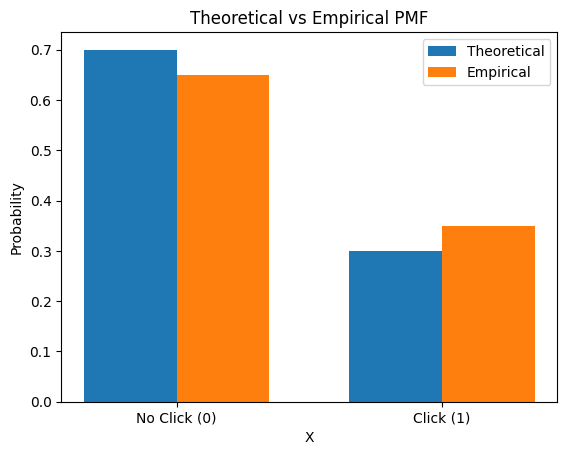

In [ ]:
import matplotlib.pyplot as plt

x = [0, 1]

theoretical_pmf = [0.70, 0.30]
empirical_pmf = [empirical_pmf_0, empirical_pmf_1]

width = 0.35

plt.bar([i - width/2 for i in x],
        theoretical_pmf,
        width=width,
        label="Theoretical")

plt.bar([i + width/2 for i in x],
        empirical_pmf,
        width=width,
        label="Empirical")

plt.xlabel("X")
plt.ylabel("Probability")
plt.title("Theoretical vs Empirical PMF")
plt.xticks(x, ["No Click (0)", "Click (1)"])
plt.legend()
plt.show()

**Step 8: Theoretical expectation**
For Bernoulli:

$$ E[X]=p $$

Therefore:

E[X]=0.30

In [ ]:
theoretical_mean = p
print("Theoretical expectation:", theoretical_mean)

Theoretical expectation: 0.3


**Step 9: Empirical expectation**

In [ ]:
empirical_mean = np.mean(samples)

print("Empirical expectation:", empirical_mean)

Empirical expectation: 0.35


**Step 10: Theoretical variance**

For a Bernoulli random variable:

$$ Var(X)=p(1-p) $$

Therefore:

$$ Var(X)=0.30(1-0.30) $$ $$ =0.30(0.70) $$
**Var(X)=0.21**
	​

In [ ]:
theoretical_variance = p * (1 - p)

print("Theoretical variance:", theoretical_variance)

Theoretical variance: 0.21


**Step 11: Empirical variance**

In [ ]:
empirical_variance = np.var(samples)

print("Empirical variance:", empirical_variance)

Empirical variance: 0.22749999999999998


**Step 12: Final result table**

In [ ]:
print("Difference P(X=0):", abs(0.70 - empirical_pmf_0))
print("Difference P(X=1):", abs(0.30 - empirical_pmf_1))
print("Difference Mean:", abs(0.30 - empirical_mean))
print("Difference Variance:", abs(0.21 - empirical_variance))

Difference P(X=0): 0.04999999999999993
Difference P(X=1): 0.04999999999999999
Difference Mean: 0.04999999999999999
Difference Variance: 0.017499999999999988


In [ ]:
import pandas as pd

result_table = pd.DataFrame({
    "Measure": [
        "P(X=0)",
        "P(X=1)",
        "Expectation",
        "Variance"
    ],

    "Theoretical value": [
        0.70,
        0.30,
        0.30,
        0.21
    ],

    "Empirical value": [
        empirical_pmf_0,
        empirical_pmf_1,
        empirical_mean,
        empirical_variance
    ]
})

result_table["Absolute difference"] = abs(
    result_table["Theoretical value"] -
    result_table["Empirical value"]
)
result_table

,Measure,Theoretical value,Empirical value,Absolute difference
0,P(X=0),0.70,0.6500,0.0500
1,P(X=1),0.30,0.3500,0.0500
2,Expectation,0.30,0.3500,0.0500
3,Variance,0.21,0.2275,0.0175


**Step 13: Effect of Sample Size**

In [ ]:
import numpy as np
import pandas as pd

sample_sizes = [10, 100, 1000, 10000]

results = []

for sample_size in sample_sizes:

    samples = np.random.binomial(n=1, p=0.30, size=sample_size)

    p0 = np.mean(samples == 0)
    p1 = np.mean(samples == 1)

    mean = np.mean(samples)
    variance = np.var(samples)

    results.append([
        sample_size,
        p0,
        p1,
        mean,
        variance
    ])

step13_table = pd.DataFrame(
    results,
    columns=[
        "Sample size",
        "Empirical P(X=0)",
        "Empirical P(X=1)",
        "Empirical mean",
        "Empirical variance"
    ]
)

step13_table.round(4)

,Sample size,Empirical P(X=0),Empirical P(X=1),Empirical mean,Empirical variance
0,10,0.8000,0.2000,0.2000,0.1600
1,100,0.7000,0.3000,0.3000,0.2100
2,1000,0.6900,0.3100,0.3100,0.2139
3,10000,0.6918,0.3082,0.3082,0.2132


In [ ]:
#PROBLEM 2

Let \(X\) denote the number of transactions flagged as potentially fraudulent in one hour. Since there are 50 independent transactions, each with a probability of 0.04 of being flagged, \(X\) follows a Binomial distribution.

$$ \boxed{X\sim Binomial(50,0.04)} $$

where:

$$ n=50,\qquad p=0.04 $$

and

$$ X\in\{0,1,2,\ldots,50\} $$

In [ ]:
import numpy as np

n = 50
p = 0.04
sample_size = 20000

samples = np.random.binomial(
    n=n,
    p=p,
    size=sample_size
)

print(samples)
print("Number of simulated hours:", len(samples))

[3 1 5 ... 3 2 2]
Number of simulated hours: 20000


In [ ]:
hours_exceeding_capacity = np.sum(samples > 4)

print("Hours exceeding capacity:", hours_exceeding_capacity)

Hours exceeding capacity: 887


In [ ]:
empirical_probability = hours_exceeding_capacity / sample_size

print("Empirical P(X > 4):", empirical_probability)

Empirical P(X > 4): 0.04435


In [ ]:
from scipy.stats import binom

n = 50
p = 0.04

theoretical_probability = 1 - binom.cdf(4, n, p)

print("Theoretical P(X > 4):", theoretical_probability)

Theoretical P(X > 4): 0.048971471884512785


In [ ]:
theoretical_mean = n * p

print("Theoretical mean:", theoretical_mean)

Theoretical mean: 2.0


In [ ]:
empirical_mean = np.mean(samples)

print("Empirical mean:", empirical_mean)



Empirical mean: 2.00385


In [ ]:
theoretical_variance = n * p * (1 - p)

print("Theoretical variance:", theoretical_variance)

Theoretical variance: 1.92


In [ ]:
empirical_variance = np.var(samples)

print("Empirical variance:", empirical_variance)

Empirical variance: 1.8639351775


In [ ]:
import pandas as pd

problem2_table = pd.DataFrame({
    "Measure": [
        "P(X > 4)",
        "Expectation",
        "Variance"
    ],

    "Theoretical value": [
        theoretical_probability,
        theoretical_mean,
        theoretical_variance
    ],

    "Empirical value": [
        empirical_probability,
        empirical_mean,
        empirical_variance
    ]
})

problem2_table["Absolute difference"] = abs(
    problem2_table["Theoretical value"] -
    problem2_table["Empirical value"]
)

print(problem2_table.round(6).to_string(index=False))

    Measure  Theoretical value  Empirical value  Absolute difference
   P(X > 4)           0.048971         0.044350             0.004621
Expectation           2.000000         2.003850             0.003850
   Variance           1.920000         1.863935             0.056065
